In [27]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain.messages import RemoveMessage  # We use this function to permenantly delet state old messages

In [28]:
load_dotenv()

True

In [29]:
model = ChatGroq(model="openai/gpt-oss-120b")

In [30]:
def chat(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}

    return {}

In [31]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

In [32]:
builder.add_edge(START, "chat")
builder.add_edge("chat", "cleanup")   # run deletion after each response
builder.add_edge("cleanup", "__end__")

In [33]:
graph = builder.compile(checkpointer=InMemorySaver())

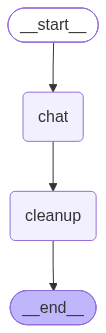

In [34]:
graph

In [35]:
config = {"configurable": {"thread_id": "t1"}}

In [36]:
# Run multiple turns
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Kuldip"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config)
# graph.invoke({"messages": [{"role": "user", "content": "What is Langchain"}]}, config)
# graph.invoke({"messages": [{"role": "user", "content": "What is Quantum Mechanics"}]}, config)
# graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI"}]}, config)
# graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content="Hi, I'm Kuldip", additional_kwargs={}, response_metadata={}, id='5d281bdc-b461-430d-9dc4-8822a3bbb8ae'),
  AIMessage(content='Hello Kuldip! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi, I\'m Kuldip". Likely they want a greeting. Should respond politely. No disallowed content. So greet them and ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 77, 'total_tokens': 142, 'completion_time': 0.136965496, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.00347774, 'prompt_tokens_details': None, 'queue_time': 0.304734389, 'total_time': 0.140443236}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_47082602e2', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e412-e18f-7391-91f7-12f6b03ab202-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={

In [37]:
snap = graph.get_state(config)
print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 6
